# 04 · LLM Comparison, Cross-Domain Robustness, Manager Summaries and Demo
*Model family 3 of 3, and the steps that turn the models into a usable tool. Requires a T4 GPU.*

| Part | What it does | Why |
|---|---|---|
| A | Prompts an LLM zero-shot and few-shot on the same test rows as models 1 and 2 | Alawwad (2026) found zero-shot LLMs weak at Arabic aspect extraction; this tests aspect-level classification |
| B | Tests the trained models on M-ABSA Arabic hotel, restaurant and laptop reviews | Youseef et al. (2026) warn that in-domain scores overstate real-world performance |
| C | Builds a manager dashboard and an LLM summary of complaints with a citation check | Turns predictions into decisions while guarding against hallucination |
| D | Gradio demo: paste a review and see its aspects and sentiment | Working prototype |

**LLM back-end** (`LLM_BACKEND` below):
* `"hf"`: an open-weight model on the Colab GPU (`Qwen/Qwen2.5-7B-Instruct`, 4-bit). No API key or cost.
* `"openrouter"`: OpenRouter free models. Add the key in Colab Secrets as `OPENROUTER_API_KEY`;
  free models are rate-limited, so keep `N_EVAL` around 300.
* `"openai"`: the OpenAI API (e.g. `gpt-4o-mini`). Add the key in Colab Secrets as `OPENAI_API_KEY`.

All back-ends use temperature 0 and a fixed seed so the results can be reproduced.

In [ ]:
# Settings, installs and data. The predictions file already holds the baseline and transformer predictions.
import os, sys, re, json, ast, time, random, subprocess, warnings, unicodedata
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

LLM_BACKEND = "hf"                          # "hf", "openrouter" or "openai"
OPENROUTER_MODEL = "meta-llama/llama-3.3-70b-instruct:free"   # any ":free" model id from openrouter.ai/models
HF_LLM = "Qwen/Qwen2.5-7B-Instruct"
OPENAI_MODEL = "gpt-4o-mini"
N_EVAL = 300                                # test rows used for the LLM comparison
K_SHOT = 2                                  # few-shot examples per class (6 in total)
SEED = 42

if IN_COLAB:
    pkgs = ["huggingface_hub", "gradio"] + (["bitsandbytes", "accelerate"] if LLM_BACKEND == "hf" else ["openai"] if LLM_BACKEND == "openai" else ["requests"])
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/MAAI902_ABSA"
else:
    BASE = "./MAAI902_ABSA"
DATA_DIR, FIG_DIR, RES_DIR, MODEL_DIR = (os.path.join(BASE, d) for d in ("data", "figures", "results", "models"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, joblib
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support, classification_report
from transformers import AutoTokenizer, AutoModelForSequenceClassification
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
LABELS = ["positive", "negative", "neutral"]
device = "cuda" if torch.cuda.is_available() else "cpu"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
preds = pd.read_csv(f"{RES_DIR}/predictions_test.csv")

def scores(y_true, y_pred):
    """Accuracy, macro-F1 and per-class precision, recall and F1."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)}
    for i, l in enumerate(LABELS):
        out[f"{l}_P"], out[f"{l}_R"], out[f"{l}_F1"] = p[i], r[i], f[i]
    return out

Mounted at /content/drive


## A. LLM prompting: zero-shot vs few-shot
Every back-end exposes the same `chat()` function, so the rest of the notebook does not depend on which one is used.

In [ ]:
def get_secret(name):
    """Read an API key from Colab Secrets, or from an environment variable outside Colab."""
    if IN_COLAB:
        from google.colab import userdata
        return userdata.get(name)
    return os.environ.get(name)

if LLM_BACKEND == "hf":
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig
    llm_tok = AutoTokenizer.from_pretrained(HF_LLM, padding_side="left")
    llm = AutoModelForCausalLM.from_pretrained(
        HF_LLM, device_map="auto",
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16, bnb_4bit_quant_type="nf4"))
    llm.eval()
    def chat(messages_batch, max_new_tokens=8):
        prompts = [llm_tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in messages_batch]
        enc = llm_tok(prompts, return_tensors="pt", padding=True).to(llm.device)
        with torch.no_grad():
            out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=llm_tok.eos_token_id)
        return [llm_tok.decode(o[enc["input_ids"].shape[1]:], skip_special_tokens=True) for o in out]
elif LLM_BACKEND == "openai":
    from openai import OpenAI
    client = OpenAI(api_key=get_secret("OPENAI_API_KEY"))
    def chat(messages_batch, max_new_tokens=8):
        outs = []
        for m in messages_batch:
            r = client.chat.completions.create(model=OPENAI_MODEL, messages=m, temperature=0, seed=SEED, max_tokens=max_new_tokens)
            outs.append(r.choices[0].message.content)
        return outs
elif LLM_BACKEND == "openrouter":
    import requests
    OR_KEY = get_secret("OPENROUTER_API_KEY")
    def chat(messages_batch, max_new_tokens=8):
        outs = []
        for m in messages_batch:
            for attempt in range(5):                     # free models are rate-limited, so retry with back-off
                r = requests.post("https://openrouter.ai/api/v1/chat/completions",
                                  headers={"Authorization": f"Bearer {OR_KEY}"},
                                  json={"model": OPENROUTER_MODEL, "messages": m, "temperature": 0, "seed": SEED, "max_tokens": max_new_tokens},
                                  timeout=60)
                if r.status_code == 200:
                    outs.append(r.json()["choices"][0]["message"]["content"] or ""); break
                time.sleep(2 ** attempt * 3)
            else:
                outs.append("")                          # counted as an invalid answer
        return outs
else:
    raise ValueError('LLM_BACKEND must be "hf", "openrouter" or "openai"')

SYSTEM = ("You are an expert annotator of Arabic hotel reviews. Given an Arabic sentence and an aspect category, "
          "decide the sentiment expressed towards THAT aspect only (ignore other aspects in the sentence). "
          "Answer with exactly one word: positive, negative or neutral.")

def user_msg(sentence, category_text):
    return f"Sentence: {sentence}\nAspect: {category_text}\nSentiment:"

# Few-shot examples: K_SHOT short training sentences per class, chosen with a fixed seed.
short = train[train.n_words <= 15]
shots = pd.concat([short[short.sentiment == l].sample(min(K_SHOT, (short.sentiment == l).sum()), random_state=SEED) for l in LABELS])
shot_msgs = []
for _, r in shots.sample(frac=1, random_state=SEED).iterrows():
    shot_msgs += [{"role": "user", "content": user_msg(r.text_light, r.category_text)}, {"role": "assistant", "content": r.sentiment}]

def build(row, few_shot):
    return [{"role": "system", "content": SYSTEM}] + (shot_msgs if few_shot else []) + [{"role": "user", "content": user_msg(row.text_light, row.category_text)}]

AR_MAP = {"إيجابي": "positive", "ايجابي": "positive", "سلبي": "negative", "محايد": "neutral"}
def parse(ans):
    """Map the LLM's answer (English or Arabic) to a label; anything else counts as invalid."""
    a = ans.strip().lower()
    for l in LABELS:
        if l in a: return l
    for k, v in AR_MAP.items():
        if k in ans: return v
    return "invalid"

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

In [ ]:
# A stratified test subset, scored by all three model families so the comparison is fair.
sub = pd.concat([test[test.sentiment == l].sample(max(1, int(round(N_EVAL * (test.sentiment == l).mean()))), random_state=SEED) for l in LABELS])
sub = sub.merge(preds[["row_id", "pred_baseline"] + (["pred_transformer"] if "pred_transformer" in preds else [])], on="row_id")
print("LLM evaluation subset:", len(sub), sub.sentiment.value_counts().to_dict())

llm_rows, BS = [], 8
for mode in ["zero_shot", "few_shot"]:
    answers, t0 = [], time.time()
    for i in range(0, len(sub), BS):
        batch = [build(r, mode == "few_shot") for _, r in sub.iloc[i:i + BS].iterrows()]
        answers += chat(batch)
    sub[f"llm_raw_{mode}"] = answers
    sub[f"pred_llm_{mode}"] = [parse(a) for a in answers]
    llm_rows.append({"mode": mode, "seconds": round(time.time() - t0, 1), "invalid_rate": (sub[f"pred_llm_{mode}"] == "invalid").mean()})
    print(mode, "done", llm_rows[-1])

LLM evaluation subset: 300 {'positive': 174, 'negative': 107, 'neutral': 19}
zero_shot done {'mode': 'zero_shot', 'seconds': 56.1, 'invalid_rate': np.float64(0.006666666666666667)}
few_shot done {'mode': 'few_shot', 'seconds': 129.7, 'invalid_rate': np.float64(0.0)}


In [ ]:
# Scores of the three model families on the same rows.
comp = {"TF-IDF baseline": scores(sub.sentiment, sub.pred_baseline)}
if "pred_transformer" in sub:
    comp["Fine-tuned transformer"] = scores(sub.sentiment, sub.pred_transformer)
comp[f"LLM zero-shot ({LLM_BACKEND})"] = scores(sub.sentiment, sub.pred_llm_zero_shot)
comp[f"LLM few-shot ({LLM_BACKEND})"] = scores(sub.sentiment, sub.pred_llm_few_shot)
comp_df = pd.DataFrame(comp).T[["accuracy", "macro_f1", "positive_F1", "negative_F1", "neutral_F1", "neutral_P", "neutral_R"]].round(4)
comp_df.to_csv(f"{RES_DIR}/04_three_family_comparison.csv")
sub.to_csv(f"{RES_DIR}/04_llm_subset_predictions.csv", index=False, encoding="utf-8-sig")
json.dump({"backend": LLM_BACKEND, "model": {"hf": HF_LLM, "openai": OPENAI_MODEL, "openrouter": OPENROUTER_MODEL}.get(LLM_BACKEND, LLM_BACKEND), "k_shot_per_class": K_SHOT,
           "n_eval": len(sub), "runs": llm_rows}, open(f"{RES_DIR}/04_llm_config.json", "w"), indent=2)
comp_df

,accuracy,macro_f1,positive_F1,negative_F1,neutral_F1,neutral_P,neutral_R
TF-IDF baseline,0.8533,0.6839,0.8946,0.8868,0.2703,0.2778,0.2632
Fine-tuned transformer,0.8433,0.7161,0.8815,0.9159,0.3509,0.2632,0.5263
LLM zero-shot (hf),0.8733,0.6671,0.9360,0.9074,0.1579,0.1579,0.1579
LLM few-shot (hf),0.8600,0.6849,0.9042,0.9067,0.2439,0.2273,0.2632


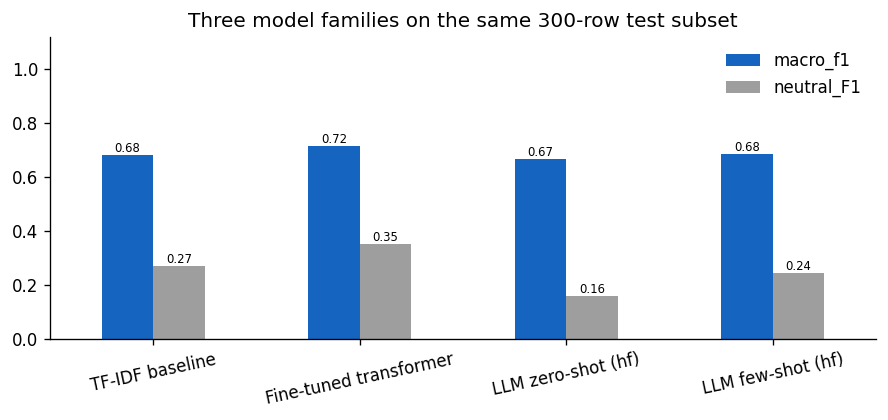

In [ ]:
# Macro-F1 and neutral F1 of each model family.
ax = comp_df[["macro_f1", "neutral_F1"]].plot.bar(figsize=(7.5, 3.6), rot=12, color=["#1565C0", "#9E9E9E"])
ax.set_ylim(0, 1.12); ax.legend(frameon=False); ax.set_title(f"Three model families on the same {len(sub)}-row test subset")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig8_three_families.png", bbox_inches="tight"); plt.show()

## B. Cross-domain robustness on M-ABSA (Arabic)
M-ABSA (Wu et al., 2025) provides Arabic test sets from other sources and domains: **hotel** (same domain,
different source), **restaurant** (a nearby domain) and **laptop** (a distant domain). The models are not
retrained, so any drop shows how well they generalise beyond SemEval hotel reviews.

In [ ]:
# The same light and full cleaning as notebook 01, so M-ABSA text reaches the models in the same form.
AR_DIAC = re.compile(r"[\u0617-\u061A\u064B-\u0652\u0670]"); TATWEEL = "ـ"
REPEAT = re.compile(r"(.)\1{2,}"); URL = re.compile(r"https?://\S+|www\.\S+"); EMOJI = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]")
def light_clean(t):
    t = unicodedata.normalize("NFKC", str(t)); t = URL.sub(" رابط ", t); t = EMOJI.sub(" ", t)
    t = AR_DIAC.sub("", t).replace(TATWEEL, ""); t = REPEAT.sub(r"\1\1", t)
    return re.sub(r"\s+", " ", t.replace("‎", "")).strip()
def full_clean(t):
    t = light_clean(t); t = re.sub("[أإآٱ]", "ا", t).replace("ى", "ي").replace("ة", "ه").replace("ؤ", "و").replace("ئ", "ي")
    return " ".join(re.sub(r"[^\u0621-\u064A\s]", " ", t).split())

DOMAINS = ["hotel", "restaurant", "laptop"]
def mabsa_lines(domain):
    """Download the Arabic test file of one M-ABSA domain from the Hugging Face Hub."""
    from huggingface_hub import list_repo_files, hf_hub_download
    files = [f for f in list_repo_files("Multilingual-NLP/M-ABSA", repo_type="dataset")
             if f.startswith(f"{domain}/ar") and "test" in f.split("/")[-1]]
    if not files: return []
    return open(hf_hub_download("Multilingual-NLP/M-ABSA", files[0], repo_type="dataset"), encoding="utf-8").read().splitlines()

POLARITY = {"positive": "positive", "pos": "positive", "negative": "negative", "neg": "negative",
            "neutral": "neutral", "neu": "neutral"}

def parse_mabsa(lines, domain):
    """Each line is `sentence####[(aspect term, category, polarity), ...]`; keep one row per opinion.
    Categories look like "rooms##cleanliness" and are turned into plain text ("rooms cleanliness")."""
    rows = []
    for ln in lines:
        if "####" not in ln: continue
        sent, lab = ln.split("####", 1)
        try: opinions = ast.literal_eval(lab.strip())
        except Exception: continue
        if opinions and isinstance(opinions[0], str):       # a single opinion written without an outer list
            opinions = [opinions]
        for op in opinions:
            op = [str(x) for x in op]
            pol = next((POLARITY[x.lower()] for x in op if x.lower() in POLARITY), None)
            if pol is None or len(op) < 3: continue
            term, cat = op[0], op[1]
            cat_text = re.sub(r"\s+", " ", re.sub(r"#+|_", " ", cat)).strip().lower()
            rows.append({"domain": domain, "sentence": sent.strip(), "aspect": term, "category_text": cat_text, "sentiment": pol})
    cols = ["domain", "sentence", "aspect", "category_text", "sentiment"]
    return pd.DataFrame(rows, columns=cols).drop_duplicates(["sentence", "category_text", "sentiment"])

xd = pd.concat([parse_mabsa(mabsa_lines(d), d) for d in DOMAINS], ignore_index=True)
xd["text_light"] = xd.sentence.map(light_clean); xd["text_full"] = xd.sentence.map(full_clean)
xd["text_full_sw"] = xd["text_full_sw_stem"] = xd["text_full"]; xd["n_words"] = xd.sentence.str.split().str.len()
# The baseline needs SemEval-style categories, so M-ABSA categories ("rooms cleanliness") are mapped back where possible.
semeval_cats = {c.replace("#", " ").replace("_", " ").lower(): c for c in train.category.unique()}
xd["category"] = xd.category_text.map(semeval_cats).fillna("UNSEEN")
print(xd.groupby("domain").sentiment.value_counts().unstack(fill_value=0))

test.txt:   0%|          | 0.00/122k [00:00<?, ?B/s]

test.txt:   0%|          | 0.00/103k [00:00<?, ?B/s]

test.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

sentiment   negative  neutral  positive
domain                                 
hotel            121       18       721
laptop           219       40       384
restaurant       167       36       482


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

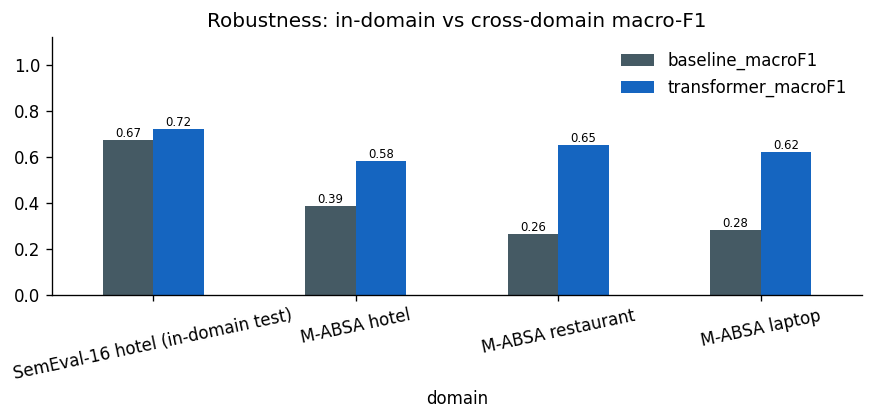

,domain,n,baseline_macroF1,transformer_macroF1
0,SemEval-16 hotel (in-domain test),2604,0.6712,0.7185
1,M-ABSA hotel,860,0.3868,0.5811
2,M-ABSA restaurant,685,0.2629,0.6512
3,M-ABSA laptop,643,0.2829,0.6215


In [ ]:
# Predict with the saved baseline and best transformer, then compare macro-F1 in-domain and on each M-ABSA domain.
base_model = joblib.load(f"{MODEL_DIR}/baseline_asc.joblib")
xd["pred_baseline"] = base_model.predict(xd)

bt_tok = AutoTokenizer.from_pretrained(f"{MODEL_DIR}/best_transformer")
bt = AutoModelForSequenceClassification.from_pretrained(f"{MODEL_DIR}/best_transformer").to(device).eval()
def bert_predict(texts, cats, bs=64):
    """Predicted label and confidence for each (sentence, aspect category) pair."""
    out, conf = [], []
    for i in range(0, len(texts), bs):
        enc = bt_tok(list(texts[i:i + bs]), list(cats[i:i + bs]), truncation=True, max_length=128, padding=True, return_tensors="pt").to(device)
        with torch.no_grad():
            p = torch.softmax(bt(**enc).logits, -1).cpu().numpy()
        out += [bt.config.id2label[int(j)] for j in p.argmax(-1)]; conf += list(p.max(-1))
    return out, conf
xd["pred_transformer"], xd["conf_transformer"] = bert_predict(xd.text_light.tolist(), xd.category_text.tolist())

semeval_ref = {"domain": "SemEval-16 hotel (in-domain test)", "n": len(preds),
               "baseline_macroF1": f1_score(preds.sentiment, preds.pred_baseline, average="macro", labels=LABELS, zero_division=0),
               "transformer_macroF1": f1_score(preds.sentiment, preds.pred_transformer, average="macro", labels=LABELS, zero_division=0) if "pred_transformer" in preds else np.nan}
xrows = [semeval_ref] + [{"domain": f"M-ABSA {d}", "n": len(g),
                          "baseline_macroF1": f1_score(g.sentiment, g.pred_baseline, average="macro", labels=LABELS, zero_division=0),
                          "transformer_macroF1": f1_score(g.sentiment, g.pred_transformer, average="macro", labels=LABELS, zero_division=0)}
                         for d, g in xd.groupby("domain", sort=False) if len(g)]
xdf = pd.DataFrame(xrows).round(4); xdf.to_csv(f"{RES_DIR}/04_cross_domain.csv", index=False)
ax = xdf.set_index("domain")[["baseline_macroF1", "transformer_macroF1"]].plot.bar(figsize=(7.5, 3.6), rot=12, color=["#455A64", "#1565C0"])
ax.set_ylim(0, 1.12); ax.legend(frameon=False); ax.set_title("Robustness: in-domain vs cross-domain macro-F1")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig9_cross_domain.png", bbox_inches="tight"); plt.show()
xdf

## C. Manager dashboard and grounded LLM summary
The test reviews stand in for a month of incoming reviews, and only the **predicted** labels are used,
as they would be in practice.

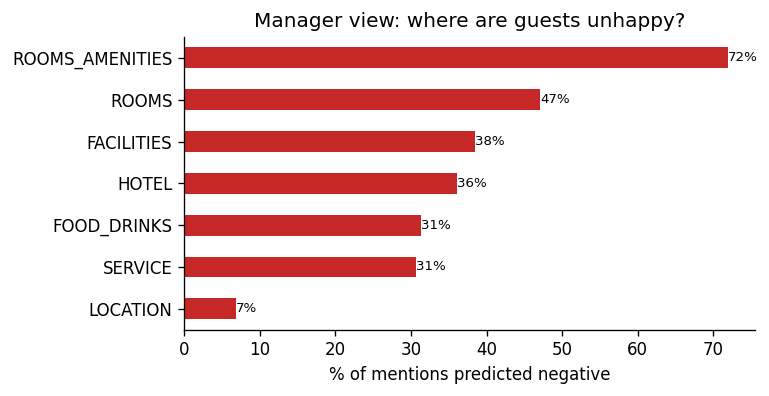

pred_transformer,positive,negative,neutral,mentions,% negative
entity,,,,,
ROOMS_AMENITIES,27,115,18,160,71.9
ROOMS,131,147,34,312,47.1
FACILITIES,172,131,37,340,38.5
HOTEL,356,250,87,693,36.1
FOOD_DRINKS,84,74,78,236,31.4
SERVICE,338,172,50,560,30.7
LOCATION,233,21,49,303,6.9


In [ ]:
# Share of negative opinions per entity: where are guests unhappy?
ENTITY_AR = {"HOTEL": "الفندق عموماً", "ROOMS": "الغرف", "ROOMS_AMENITIES": "تجهيزات الغرف", "FACILITIES": "المرافق",
             "SERVICE": "الخدمة والموظفون", "LOCATION": "الموقع", "FOOD_DRINKS": "الطعام والشراب"}
dash = preds.groupby("entity")["pred_transformer" if "pred_transformer" in preds else "pred_baseline"].value_counts().unstack(fill_value=0)
dash = dash.reindex(columns=LABELS, fill_value=0)
dash["mentions"] = dash.sum(axis=1); dash["% negative"] = (100 * dash.negative / dash.mentions).round(1)
dash = dash.sort_values("% negative", ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
dash["% negative"].plot.barh(ax=ax, color="#C62828"); ax.invert_yaxis()
ax.set_xlabel("% of mentions predicted negative"); ax.set_ylabel(""); ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=8)
ax.set_title("Manager view: where are guests unhappy?")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig10_manager_dashboard.png", bbox_inches="tight"); plt.show()
dash

In [ ]:
# For the three most-complained-about entities, the LLM summarises the negative sentences. It may only use the
# numbered sentences it is given and must cite them, e.g. [3, 7]; citations to sentences that do not exist are flagged.
SUMMARY_SYSTEM = ("You are a hotel guest-experience analyst. Write for a hotel manager in the UAE. Use ONLY the numbered guest sentences "
                  "and statistics provided – do not invent facts. After every point, cite the supporting sentence numbers in brackets, e.g. [3, 7].")
def summary_prompt(entity, stats, sentences):
    lines = "\n".join(f"{i+1}. {s}" for i, s in enumerate(sentences))
    return (f"Aspect: {entity} ({ENTITY_AR.get(entity, '')})\nStatistics: {stats}\n\nNegative guest sentences (Arabic):\n{lines}\n\n"
            "Write: (1) a 2–3 bullet summary of the main complaints in English, (2) the same summary in Arabic, "
            "(3) one concrete recommended action. Keep it under 120 words.")

pcol = "pred_transformer" if "pred_transformer" in preds else "pred_baseline"
summaries = []
for entity in dash.index[:3]:
    negs = preds[(preds.entity == entity) & (preds[pcol] == "negative")].sentence.drop_duplicates().head(15).tolist()
    if not negs: continue
    stats = f"{int(dash.loc[entity, 'mentions'])} mentions, {dash.loc[entity, '% negative']}% negative"
    msg = [{"role": "system", "content": SUMMARY_SYSTEM}, {"role": "user", "content": summary_prompt(entity, stats, negs)}]
    text = chat([msg], max_new_tokens=350)[0]
    cited = {int(n) for grp in re.findall(r"\[([\d,\s]+)\]", text) for n in re.findall(r"\d+", grp)}
    summaries.append({"entity": entity, "n_negative_sentences": len(negs), "summary": text,
                      "citations_found": len(cited), "invalid_citations": sorted(n for n in cited if n < 1 or n > len(negs))})
    print(f"\n===== {entity} =====\n{text}\n→ citations: {sorted(cited)} | invalid: {summaries[-1]['invalid_citations']}")
json.dump(summaries, open(f"{RES_DIR}/04_manager_summaries.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)


===== ROOMS_AMENITIES =====
(1) Main complaints include delayed room service, inadequate amenities like non-functional TVs and air conditioning, poor lighting, and issues with plumbing and heating. [1, 2, 3, 4, 5, 7, 10, 11, 12, 13, 14, 15]
(2) شكاوى رئيسية تشمل تأخير تسليم الغرف، نقص الكماليات مثل الأجهزة الكهربائية غير السليمة والتهوية غير الكافية، إضاءة غير كافية، مشاكل في الأنابيب، ونقص التدفئة المركزية. [1, 2, 3, 4, 5, 7, 10, 11, 12, 13, 14, 15]
(3) Ensure all rooms are thoroughly checked before guests arrive to address any issues promptly, provide adequate amenities, and maintain proper maintenance schedules for facilities. [1, 2, 3, 4, 5, 7, 10, 11, 12, 13, 14, 15]
→ citations: [1, 2, 3, 4, 5, 7, 10, 11, 12, 13, 14, 15] | invalid: []

===== ROOMS =====
(1) Main complaints include small and dirty rooms, outdated facilities, and poor service. Guests also reported issues with plumbing, infestations, and misallocated rooms. [3, 4, 5, 6, 7, 10, 11, 13, 14]
(1) main complaints هم الغ

**Grounding check:** each summary point should be supported by the sentences it cites. Any claim that is not
supported by its cited sentences is counted as a hallucination.

## D. Interactive demo (Gradio)
Paste any Arabic hotel review. It is split into sentences, the aspect detector from notebook 02 finds the
entities each sentence mentions, and the best fine-tuned transformer classifies the sentiment towards each one.
Colab prints a public link to the demo.

In [ ]:
# Load the aspect detector from notebook 02 and map each entity to a category text the sentiment model knows.
acd_bundle = joblib.load(f"{MODEL_DIR}/baseline_acd.joblib")
ENTITY_QUERY = {"HOTEL": "hotel general", "ROOMS": "rooms general", "ROOMS_AMENITIES": "rooms amenities general",
                "FACILITIES": "facilities general", "SERVICE": "service general", "LOCATION": "location general",
                "FOOD_DRINKS": "food drinks quality"}

ENTITY_EN = {"HOTEL": "Hotel overall", "ROOMS": "Rooms", "ROOMS_AMENITIES": "Room amenities", "FACILITIES": "Facilities",
             "SERVICE": "Service & staff", "LOCATION": "Location", "FOOD_DRINKS": "Food & drinks"}

def analyse_review(review):
    """Full pipeline for one review: split, detect aspects, classify sentiment."""
    sents = [s.strip() for s in re.split(r"[.!؟?\n،]+|\s(?:لكن|ولكن|بس)\s", review) if len(s.strip().split()) >= 2]
    rows = []
    for s in sents:
        probs = acd_bundle["model"].predict_proba([full_clean(s)])[0]
        ents = [e for e, p in zip(acd_bundle["mlb"].classes_, probs) if p >= acd_bundle["threshold"]] or [acd_bundle["mlb"].classes_[int(probs.argmax())]]
        lab, conf = bert_predict([light_clean(s)] * len(ents), [ENTITY_QUERY.get(e, e.lower()) for e in ents])
        rows += [{"sentence": s, "aspect": e, "sentiment": l, "confidence": round(float(c), 2)}
                 for e, l, c in zip(ents, lab, conf)]
    return pd.DataFrame(rows, columns=["sentence", "aspect", "sentiment", "confidence"])

demo_text = "الغرفة كانت وسخة والمكيف ما يشتغل، لكن الموظفين كانوا متعاونين جداً والموقع ممتاز. الفطور عادي"
print(analyse_review(demo_text))

                                     sentence           aspect sentiment  \
0           الغرفة كانت وسخة والمكيف ما يشتغل            ROOMS  negative   
1           الغرفة كانت وسخة والمكيف ما يشتغل  ROOMS_AMENITIES  negative   
2  الموظفين كانوا متعاونين جداً والموقع ممتاز         LOCATION  positive   
3  الموظفين كانوا متعاونين جداً والموقع ممتاز          SERVICE  positive   
4                                 الفطور عادي      FOOD_DRINKS   neutral   

   confidence  
0        0.98  
1        0.98  
2        0.99  
3        0.99  
4        0.92  


The demo shows the same results as a small table: each sentence of the review, the aspect it talks about,
the predicted sentiment and how confident the model is.

In [ ]:
import html as html_lib

def render_results(review):
    """Run the pipeline and return the results as an HTML table for the demo page."""
    df = analyse_review(review or "")
    if df.empty:
        return "<p class='empty'>Write at least one sentence of two or more words.</p>"
    body = ""
    for r in df.itertuples():
        body += (f"<tr><td class='sent' dir='rtl'>{html_lib.escape(r.sentence)}</td>"
                 f"<td>{ENTITY_EN.get(r.aspect, r.aspect)}<span class='ar'>{ENTITY_AR.get(r.aspect, '')}</span></td>"
                 f"<td><span class='tag {r.sentiment}'>{r.sentiment}</span></td>"
                 f"<td class='conf'>{r.confidence:.0%}</td></tr>")
    return ("<table class='results'><thead><tr><th>Sentence</th><th>Aspect</th><th>Sentiment</th>"
            f"<th>Confidence</th></tr></thead><tbody>{body}</tbody></table>")

DEMO_CSS = """
.gradio-container {background: #fdf3f6 !important; max-width: 980px !important; margin: auto;}
h1, h2, h3, p, label, span {color: #4a2a35;}
.intro p {font-size: 15px; line-height: 1.6;}
textarea {font-size: 17px !important; line-height: 1.8 !important;}
.results {width: 100%; border-collapse: collapse; background: #ffffff; border-radius: 10px; overflow: hidden;}
.results th {background: #f7dbe3; color: #4a2a35; text-align: left; padding: 10px 12px; font-weight: 600;}
.results td {padding: 10px 12px; border-top: 1px solid #f3e1e7; vertical-align: middle;}
.results td.sent {font-size: 16px; text-align: right;}
.results .ar {display: block; font-size: 12px; color: #9b6b7a;}
.results td.conf {color: #7a5562; font-variant-numeric: tabular-nums;}
.tag {padding: 3px 10px; border-radius: 999px; font-size: 13px; font-weight: 600;}
.tag.positive {background: #e2f2ea; color: #23694a;}
.tag.negative {background: #fbd9e2; color: #a3274d;}
.tag.neutral {background: #eeeaec; color: #5c5357;}
.results th, .results td {border-left: none !important; border-right: none !important; border-color: #f3e1e7 !important;}
.empty {color: #9b6b7a;}
footer {display: none !important;}
"""
FORCE_LIGHT = "() => { document.body.classList.remove('dark'); }"

EXAMPLES = [demo_text,
            "الموقع ممتاز وقريب من المترو، بس الفطور كان بارد والخدمة بطيئة",
            "غرفة واسعة ونظيفة والسرير مريح جدا، لكن السعر مرتفع شوي"]

import inspect
import gradio as gr
theme = gr.themes.Soft(primary_hue="pink", neutral_hue="stone",
                       font=[gr.themes.GoogleFont("IBM Plex Sans Arabic"), "sans-serif"]).set(
    body_background_fill="#fdf3f6", block_background_fill="#ffffff", block_border_color="#f3d3dc",
    button_primary_background_fill="#e9a3b8", button_primary_background_fill_hover="#df8ea6",
    button_primary_text_color="#ffffff")
style = {"theme": theme, "css": DEMO_CSS, "js": FORCE_LIGHT}
# Newer Gradio versions take the styling in launch(), older ones in Blocks()
in_blocks = {k: v for k, v in style.items() if k in inspect.signature(gr.Blocks).parameters}
in_launch = {k: v for k, v in style.items() if k not in in_blocks}
with gr.Blocks(title="Hotel review analysis", **in_blocks) as demo:
    gr.Markdown("## Hotel review analysis\nPaste an Arabic hotel review to see what the guest liked and disliked, "
                "aspect by aspect.", elem_classes="intro")
    inp = gr.Textbox(lines=3, label="Review (Arabic)", value=demo_text, rtl=True)
    btn = gr.Button("Analyse review", variant="primary")
    out = gr.HTML(render_results(demo_text))
    gr.Examples(EXAMPLES, inputs=inp, label="Try another review")
    btn.click(render_results, inp, out)
demo.launch(share=True, debug=False, **in_launch)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b945bb5da502cbdfb0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
